In [1]:
import numpy as np
import torch

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

# 0. Choosing "teacher" model

In [2]:
checkpoint = "bert-base-uncased"
task_name  = "stsb"

# 1. Loading our mrpc part of the GLUE dataset

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer, DataCollatorWithPadding

raw_datasets = load_dataset("glue", task_name)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating test split: 100%|██████████| 1379/1379 [00:00<00:00, 919107.77 examples/s]


In [4]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 5749
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1379
    })
})

In [5]:
raw_datasets['train']

Dataset({
    features: ['sentence1', 'sentence2', 'label', 'idx'],
    num_rows: 5749
})

In [6]:
from datasets import DatasetDict

In [7]:
raw_datasets = DatasetDict({
    "train": raw_datasets['train'],
    "validation": raw_datasets['validation'],
    "test": raw_datasets['test']
})

In [8]:
raw_datasets

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 5749
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1379
    })
})

In [9]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[0]

{'sentence1': 'A plane is taking off.',
 'sentence2': 'An air plane is taking off.',
 'label': 5.0,
 'idx': 0}

In [10]:
raw_train_dataset[5]['sentence1']

'Some men are fighting.'

In [11]:
raw_train_dataset[5]['sentence2']

'Two men are fighting.'

In [12]:
raw_train_dataset[5]['idx']

5

In [13]:
raw_train_dataset.features

{'sentence1': Value('string'),
 'sentence2': Value('string'),
 'label': Value('float32'),
 'idx': Value('int32')}

# 2. Preprocess

In [14]:
def tokenize_function(example):
    return tokenizer(example["sentence1"], example["sentence2"], truncation=True)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
tokenized_datasets

Map: 100%|██████████| 1379/1379 [00:00<00:00, 74842.07 examples/s]


DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 5749
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1379
    })
})

# 3. Preparing for Training

In [15]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [16]:
tokenized_datasets = tokenized_datasets.remove_columns(["sentence1", "sentence2", "idx"])
tokenized_datasets = tokenized_datasets.rename_column("label", "labels")
tokenized_datasets.set_format("torch")
tokenized_datasets["train"].column_names

['labels', 'input_ids', 'token_type_ids', 'attention_mask']

In [17]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    tokenized_datasets["train"], shuffle=True, batch_size=32, collate_fn=data_collator
)

val_dataloader = DataLoader(
    tokenized_datasets["validation"], batch_size=32, collate_fn=data_collator
)

eval_dataloader = DataLoader(
    tokenized_datasets["test"], batch_size=32, collate_fn=data_collator
)

In [18]:
for batch in train_dataloader:
    break
{k: v.shape for k, v in batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 66]),
 'token_type_ids': torch.Size([32, 66]),
 'attention_mask': torch.Size([32, 66])}

In [19]:
run_layer = [
    {
        "times": 2,
        "run_heads": True,
        "run_wo": {"run": True, "times": 1},
        "run_ffn": True,
    }
    for _ in range(6)
]

run_layer

[{'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True}]

# 4. Load Model

In [20]:
import sys
sys.path.insert(0, '../')

In [21]:
from Bert_model.modeling_bert_para_sharing import BertForSequenceClassification

In [24]:
num_labels = 1

In [25]:
model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    problem_type="regression",
    # id2label=id2label,
    # label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [26]:
model.set_use_module_grafting(False)
model.set_use_scc_status(False)

In [27]:
outputs = model(**batch)
print(outputs.loss, outputs.logits.shape)

tensor(4.9161, grad_fn=<MseLossBackward0>) torch.Size([32, 1])


In [28]:
teacher_model = BertForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=num_labels,
    problem_type="regression",
    # id2label=id2label,
    # label2id=label2id,
    output_hidden_states=True,
    output_attentions=True
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [29]:
teacher_model.set_use_module_grafting(False)
teacher_model.set_use_scc_status(False)

In [30]:
outputs = teacher_model(**batch)
print(outputs.loss, outputs.logits.shape)

tensor(10.6868, grad_fn=<MseLossBackward0>) torch.Size([32, 1])


In [31]:
device = torch.device("cuda:1") if torch.cuda.is_available() else torch.device("cpu")
model.to(device)
teacher_model.to(device)

device

device(type='cuda', index=1)

### Load Trained Weights

In [32]:
load_path = '../glue_fine_tune/weights/'
best_weight = torch.load(load_path + f'bert-{task_name}.pt', map_location=device)
model.load_state_dict(best_weight['model_state_dict'])
teacher_model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [33]:
from train_eval_func import eval_loop

In [34]:
test_run_layer = [
    {
        "times": 1,
        "run_heads": True,
        "run_wo": {"run": True, "times": 1},
        "run_ffn": True,
    }
    for _ in range(12)
]

In [35]:
eval_loop(model, val_dataloader, task_name, device, run_layer=test_run_layer, regression=True)

({'pearson': 0.900084701022039, 'spearmanr': 0.8962584593578651},
 0.4520208261748578)

In [36]:
eval_loop(teacher_model, val_dataloader, task_name, device, regression=True)

({'pearson': 0.900084701022039, 'spearmanr': 0.8962584593578651},
 0.4520208261748578)

In [37]:
for i in range(11, 0, -2):
    del model.bert.encoder.layer[i]

In [38]:
model.bert.encoder.layer

ModuleList(
  (0-5): 6 x BertLayer(
    (attention): BertAttention(
      (self): BertSelfAttention(
        (query): Linear(in_features=768, out_features=768, bias=True)
        (key): Linear(in_features=768, out_features=768, bias=True)
        (value): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (output): BertSelfOutput(
        (dense): Linear(in_features=768, out_features=768, bias=True)
        (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
    )
    (intermediate): BertIntermediate(
      (dense): Linear(in_features=768, out_features=3072, bias=True)
      (intermediate_act_fn): GELUActivation()
    )
    (output): BertOutput(
      (dense): Linear(in_features=3072, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
)

In [39]:
eval_loop(model, val_dataloader, task_name, device, run_layer=run_layer, regression=True)

({'pearson': 0.7572656379863136, 'spearmanr': 0.7665534108875871},
 1.8071656949976658)

# 5. Learning Rate and Leanring Scheduler Setup

In [40]:
from torch.optim import AdamW

optimizer = AdamW(model.parameters(), lr=3e-5)

In [41]:
from train_eval_func import set_lr_scheduler

num_epochs = 10
num_training_steps = num_epochs * len(train_dataloader)

lr_scheduler = set_lr_scheduler(
    optimizer          = optimizer,
    num_training_steps = num_training_steps
)

print(num_training_steps)

1800


In [42]:
patience=3
save_path=f'./weights/bert-{task_name}.pt'

# 6. Training

In [43]:
from train_eval_func import train

In [44]:
train_stats = train(
    model,
    train_dataloader,
    val_dataloader,
    task_name,
    device,
    num_epochs=num_epochs,
    lr=lr_scheduler,
    patience=patience,
    use_early_stopping=True,
    optimizer=optimizer,
    lr_scheduler=lr_scheduler,
    save_path=save_path,
    display_epoch_iter=True,
    run_layer=run_layer,
    teacher_model=teacher_model,
    regression=True
)

Training:   0%|          | 0/1800 [00:00<?, ?it/s]

Knowledge distillation used!


/home/abhinavl/work/Layer_Graft/layer-grafting-publication/para_sharing_test/../train_eval_func.py:241: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:835.)
  total_loss += float(loss)
Training:  10%|█         | 180/1800 [00:37<05:17,  5.10it/s]

✓ Saved checkpoint (best loss: 0.5516)

<----------------- Epoch 1 ----------------->
Loss: 0.21, Training Metrics:
  pearson: 0.8964
  spearmanr: 0.8799
Validation Loss: 0.55, Validation Metrics:
  pearson: 0.8773
  spearmanr: 0.8731
Elapsed Time: 40.0435 sec


Training:  20%|██        | 360/1800 [01:22<03:31,  6.81it/s]  

✓ Saved checkpoint (best loss: 0.5182)

<----------------- Epoch 2 ----------------->
Loss: 0.12, Training Metrics:
  pearson: 0.9443
  spearmanr: 0.9342
Validation Loss: 0.52, Validation Metrics:
  pearson: 0.8836
  spearmanr: 0.8784
Elapsed Time: 37.1876 sec


... (8 outputs left out)

Training:  70%|███████   | 1260/1800 [05:14<02:05,  4.30it/s]


<----------------- Epoch 7 ----------------->
Loss: 0.04, Training Metrics:
  pearson: 0.9817
  spearmanr: 0.9792
Validation Loss: 0.51, Validation Metrics:
  pearson: 0.8839
  spearmanr: 0.8791
Elapsed Time: 46.9064 sec


Training:  80%|████████  | 1440/1800 [06:04<01:31,  3.95it/s]


<----------------- Epoch 8 ----------------->
Loss: 0.03, Training Metrics:
  pearson: 0.9838
  spearmanr: 0.9816
Validation Loss: 0.5, Validation Metrics:
  pearson: 0.8850
  spearmanr: 0.8806
Elapsed Time: 46.9544 sec
>>>>> Early stopping callback <<<<<

Total Training Time: 364.58 sec
Chosen Primary Metric: pearson
Best Metric Run: 0.8859


### Plotting Loss

In [45]:
from train_eval_func import plotLoss, plotAccuracy

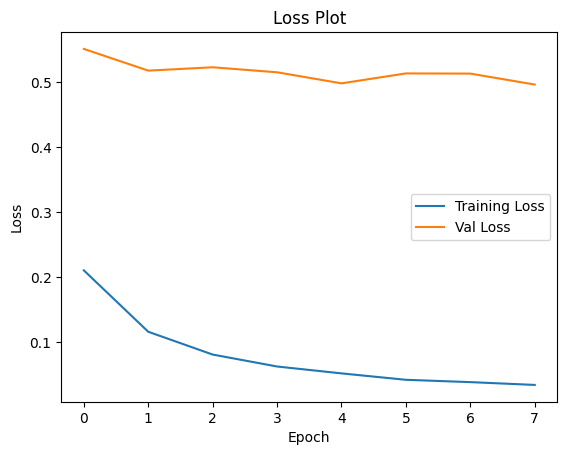

In [46]:
plotLoss(train_stats['train_losses'], train_stats['val_losses'], title="Loss Plot")

### Plotting Accuracy

In [47]:
def getMetricList(train_stats, metric_name='accuracy'):
    train_values = [m[metric_name] for m in train_stats['train_metrics_history']]
    val_values = [m[metric_name] for m in train_stats['val_metrics_history']]

    return train_values, val_values

In [48]:
train_values, val_values = getMetricList(train_stats)

KeyError: 'accuracy'

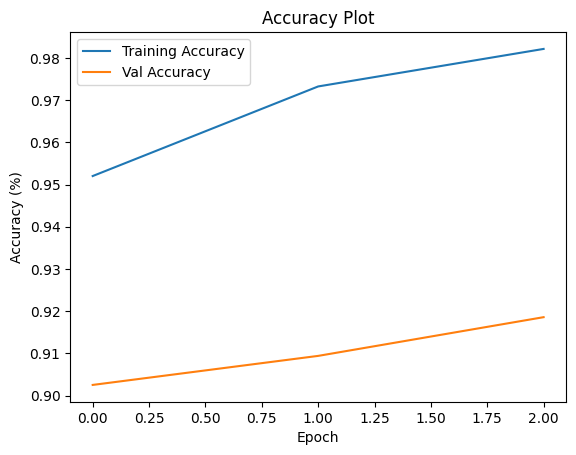

In [47]:
plotAccuracy(train_values, val_values, title="Accuracy Plot")

In [48]:
train_values, val_values = getMetricList(train_stats, 'f1')

KeyError: 'f1'

In [ ]:
plotAccuracy(train_values, val_values, legend=["Training F1", "Val F1"], title="F1 Plot", xlabel="F1 Score")

# 7. Evaluation

In [49]:
best_weight = torch.load(save_path)

In [50]:
model.load_state_dict(best_weight['model_state_dict'])

<All keys matched successfully>

In [54]:
eval_loop(model, val_dataloader, task_name, device, run_layer=run_layer, regression=True)[0]

{'pearson': 0.8858951169580997, 'spearmanr': 0.8809307370498928}

In [52]:
best_weight['epoch']

5

In [53]:
run_layer

[{'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True},
 {'times': 2,
  'run_heads': True,
  'run_wo': {'run': True, 'times': 1},
  'run_ffn': True}]

In [ ]:
model.bert.encoder.layer